In [6]:
%pip install pandas matplotlib seaborn

In [20]:
import pandas as pd

orders = pd.read_csv("orders.csv", parse_dates=["order_date"])
items = pd.read_csv("order_items.csv")
products = pd.read_csv("products.csv")
customers = pd.read_csv("customers.csv")

print(orders.shape, items.shape, products.shape, customers.shape)

(9245, 7) (15608, 5) (90, 5) (3600, 4)


In [21]:
print(orders["order_id"].duplicated().sum())

38


In [22]:
print(products["category"].value_counts())

category
Kitchen       10
Bath           9
Furniture      9
Outdoor        9
Bedding        8
Lighting       8
Decor          8
Storage        7
decor          4
 Kitchen       2
 Bedding       2
Storage        2
Kitchen        1
kitchen        1
KITCHEN        1
bedding        1
BEDDING        1
bath           1
Furniture      1
furniture      1
FURNITURE      1
LIGHTING       1
OUTDOOR        1
 Outdoor       1
Name: count, dtype: int64


In [23]:
print(orders["status"].value_counts())

status
completed    8490
returned      409
canceled      346
Name: count, dtype: int64


In [24]:
print(items["unit_price"].isna().sum())

199


In [25]:
print("Before:", len(orders))
orders = orders.drop_duplicates()
print("After:", len(orders))

Before: 9245
After: 9207


In [26]:
products["category"] = products["category"].str.strip().str.title()
print(products["category"].value_counts())

category
Kitchen      15
Bedding      12
Furniture    12
Decor        12
Outdoor      11
Bath         10
Lighting      9
Storage       9
Name: count, dtype: int64


In [27]:
median_price = items.groupby("product_id")["unit_price"].transform("median")
items["unit_price"] = items["unit_price"].fillna(median_price)

items = items.merge(products[["product_id", "list_price"]], on="product_id", how="left")
items["unit_price"] = items["unit_price"].fillna(items["list_price"])
items = items.drop(columns="list_price")

print(items["unit_price"].isna().sum())

0


In [28]:
items["line_revenue"] = items["quantity"] * items["unit_price"] - items["discount_amount"]

In [29]:
order_rev = items.groupby("order_id")["line_revenue"].sum().rename("order_revenue").reset_index()
orders = orders.merge(order_rev, on="order_id", how="left")

orders["is_revenue"] = orders["status"] == "completed"
orders["year"] = orders["order_date"].dt.year
orders["month"] = orders["order_date"].dt.to_period("M")

In [34]:
print(orders["order_revenue"].isna().sum())
print(orders["order_id"].is_unique)
print(orders.groupby("status")["order_revenue"].agg(["count", "sum"]).round(0))

completed = orders[orders["is_revenue"]]
print(completed.groupby("year")["order_revenue"].sum().round(0))

0
True
           count        sum
status                     
canceled     344    75935.0
completed   8456  1882080.0
returned     407   116956.0
year
2024     851158.0
2025    1030922.0
Name: order_revenue, dtype: float64


In [41]:
completed = orders[orders["is_revenue"]].copy()
completed["month_num"] = completed["order_date"].dt.month

monthly = completed.pivot_table(index="month_num", columns="year",
                                values="order_revenue", aggfunc="sum")
monthly["growth_pct"] = (monthly[2025] / monthly[2024] - 1) * 100
print(monthly.round(1))

year           2024      2025  growth_pct
month_num                                
1           54397.2   73066.4        34.3
2           63291.1   70476.8        11.4
3           71782.1   78756.9         9.7
4           64783.1   79917.7        23.4
5           73698.4   83137.0        12.8
6           67235.6   92262.3        37.2
7           77304.3   83407.0         7.9
8           62743.2   91499.7        45.8
9           60055.3   75212.6        25.2
10          68472.6   82020.0        19.8
11         100615.9  130028.9        29.2
12          86779.2   91136.7         5.0


<ipython-input-45-99bb542959ee>:14: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("charts/01_monthly_revenue.png", dpi=150, bbox_inches="tight")
<ipython-input-45-99bb542959ee>:14: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("charts/01_monthly_revenue.png", dpi=150, bbox_inches="tight")


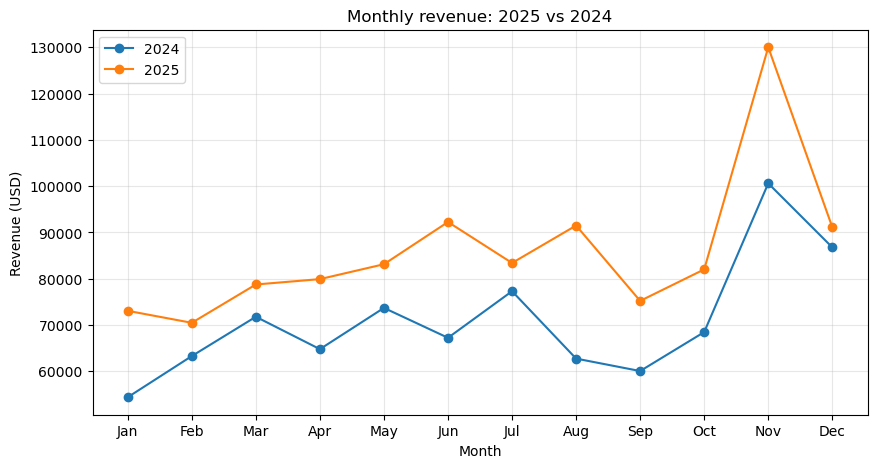

In [45]:
import matplotlib.pyplot as plt
import os
os.makedirs("charts", exist_ok=True)

months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
plt.figure(figsize=(10, 5))
plt.plot(months, monthly[2024], marker="o", label="2024")
plt.plot(months, monthly[2025], marker="o", label="2025")
plt.title("Monthly revenue: 2025 vs 2024")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("charts/01_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
lines = (items
         .merge(orders[["order_id", "status", "order_date", "year"]], on="order_id")
         .merge(products[["product_id", "product_name", "category"]], on="product_id"))

sales = lines[lines["status"] == "completed"].copy()
sales["quarter"] = sales["order_date"].dt.quarter

print(sales.shape)

(14283, 12)


In [49]:
cat = sales.pivot_table(index="category", columns="year",
                        values="line_revenue", aggfunc="sum")
cat["growth_pct"] = (cat[2025] / cat[2024] - 1) * 100
cat["share_2025_pct"] = cat[2025] / cat[2025].sum() * 100
print(cat.sort_values(2025, ascending=False).round(1))

year           2024      2025  growth_pct  share_2025_pct
category                                                 
Furniture  144464.8  178451.6        23.5            17.3
Kitchen    123746.6  156104.6        26.1            15.1
Decor      127210.6  150815.0        18.6            14.6
Bedding    123854.3  143176.6        15.6            13.9
Lighting   106222.6  131653.2        23.9            12.8
Outdoor    117207.1  130426.3        11.3            12.7
Storage     58038.7   81675.5        40.7             7.9
Bath        50413.4   58619.3        16.3             5.7


<ipython-input-53-caeed3cf61f0>:8: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("charts/02_category_revenue.png", dpi=150, bbox_inches="tight")
<ipython-input-53-caeed3cf61f0>:8: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("charts/02_category_revenue.png", dpi=150, bbox_inches="tight")


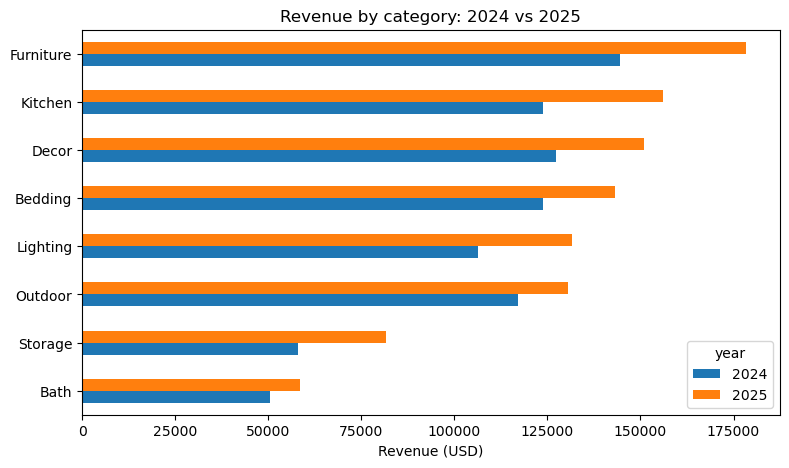

In [53]:
import matplotlib.pyplot as plt

order = cat.sort_values(2025, ascending=True)
order[[2024, 2025]].plot(kind="barh", figsize=(9, 5))
plt.title("Revenue by category: 2024 vs 2025")
plt.xlabel("Revenue (USD)")
plt.ylabel("")
plt.savefig("charts/02_category_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [54]:
top = (sales.groupby(["product_name", "category"])
       .agg(revenue=("line_revenue", "sum"), units=("quantity", "sum"))
       .sort_values("revenue", ascending=False)
       .head(10))
print(top.round(0))

                                     revenue  units
product_name              category                 
Cotton Patio Chair        Outdoor    67035.0    142
Classic Dining Chair Pair Furniture  52057.0     67
Coastal Picture Frame Set Decor      44242.0    310
Ceramic Quilt             Bedding    41400.0    194
Bamboo Nightstand         Furniture  41366.0     77
Modern Wreath             Decor      41037.0    296
Nordic Side Table         Furniture  40366.0     73
Velvet String Lights      Lighting   38850.0    168
Classic Garland           Decor      38681.0    288
Marble Bookshelf          Furniture  38596.0     80


In [55]:
mix = sales.pivot_table(index="quarter", columns="category",
                        values="line_revenue", aggfunc="sum")
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
print(mix_pct.round(1))

category  Bath  Bedding  Decor  Furniture  Kitchen  Lighting  Outdoor  Storage
quarter                                                                       
1          6.3     15.8   14.0       19.3     16.3      13.8      5.6      8.9
2          5.8     12.6   11.8       14.3     13.2      11.3     24.9      6.1
3          5.3     13.5   11.9       16.0     13.6      13.2     19.1      7.4
4          5.9     14.9   20.1       18.8     16.2      12.3      4.2      7.5


<ipython-input-56-8e39d5d7890b>:7: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("charts/03_category_mix.png", dpi=150, bbox_inches="tight")
<ipython-input-56-8e39d5d7890b>:7: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("charts/03_category_mix.png", dpi=150, bbox_inches="tight")


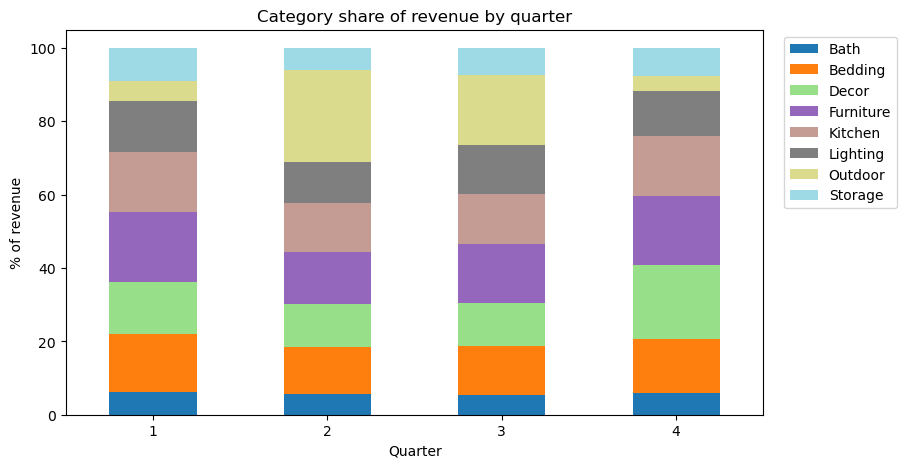

In [56]:
mix_pct.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab20")
plt.title("Category share of revenue by quarter")
plt.xlabel("Quarter")
plt.ylabel("% of revenue")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.savefig("charts/03_category_mix.png", dpi=150, bbox_inches="tight")
plt.show()

In [57]:
oc = (lines.groupby(["order_id", "category"])
      .agg(cat_revenue=("line_revenue", "sum"), status=("status", "first"))
      .reset_index())
print(oc.shape)

(14336, 4)


In [58]:
rates = pd.crosstab(oc["category"], oc["status"])
rates["orders"] = rates.sum(axis=1)
rates["return_rate_pct"] = rates["returned"] / rates["orders"] * 100
rates["cancel_rate_pct"] = rates["canceled"] / rates["orders"] * 100
rates["lost_pct"] = rates["return_rate_pct"] + rates["cancel_rate_pct"]

In [59]:
aov = (oc[oc["status"] == "completed"]
       .groupby("category")["cat_revenue"].mean().rename("aov"))

summary = rates.join(aov).sort_values("lost_pct", ascending=False)
print(summary[["orders", "return_rate_pct", "cancel_rate_pct", "lost_pct", "aov"]].round(1))

           orders  return_rate_pct  cancel_rate_pct  lost_pct    aov
category                                                            
Furniture    1007             11.7              3.1      14.8  376.4
Bath         1643              4.4              4.6       9.0   72.9
Bedding      1800              5.1              3.3       8.3  161.8
Outdoor      1353              4.4              3.7       8.1  199.2
Kitchen      2844              4.1              3.8       7.9  106.9
Decor        2729              4.2              3.5       7.7  110.3
Storage      1733              4.2              3.3       7.5   87.2
Lighting     1227              4.0              2.9       6.9  208.3


<ipython-input-60-b2472efb676e>:6: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("charts/04_return_rate.png", dpi=150, bbox_inches="tight")
<ipython-input-60-b2472efb676e>:6: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("charts/04_return_rate.png", dpi=150, bbox_inches="tight")


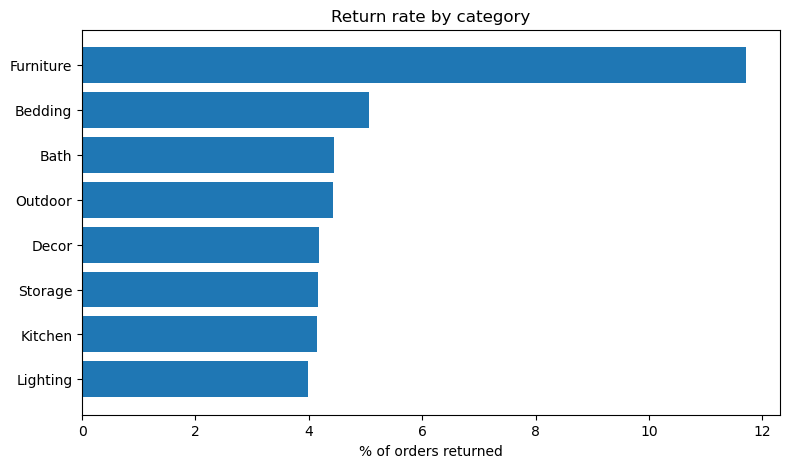

In [60]:
s = summary.sort_values("return_rate_pct")
plt.figure(figsize=(9, 5))
plt.barh(s.index, s["return_rate_pct"])
plt.title("Return rate by category")
plt.xlabel("% of orders returned")
plt.savefig("charts/04_return_rate.png", dpi=150, bbox_inches="tight")
plt.show()